# 2 · Rottnest physical resources for the converged run

This notebook reconstructs the **chemically accurate frame-111 experiment from notebook 1** with `rxn.convergence_config()`: HF initialization, nominal filter 500, implemented cutoff 200, dissipative step 0.1, rank-four low-rank Hamiltonian simulation with 8 inner steps, and **1,500 sampled W applications** with seed 123.

It checks the energy against the original N=3 Hamiltonian before estimating resources. It passes the actual Cirq block references and the ordered sampled sequence to Rottnest. Repeated blocks remain cached; the full gate-expanded reaction circuit is never assembled here. Since this is a one-geometry run, “one Hamiltonian” and “full configured run” are the same workload and are estimated once.

Tables and plots are displayed inline. No separate permanent run artifacts are saved; temporary worker interchange files are deleted. The owner-supplied executables and reaction data remain unchanged.

Rottnest reports **tocks**, region **space-time volumes**, **T-factory sources**, and its synthesis counts. The layout and error assumptions are displayed. These are the **unitary W costs**; state preparation, ancilla resets, energy readout and nonunitary contextual projection need additional hardware models. No undocumented conversion to seconds or physical-qubit counts is applied.

In [1]:
from pathlib import Path
import os, sys
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
ROOT = next(p for p in (Path.cwd(), Path.cwd()/"newer")
            if (p/"entire_rxn_with_circuit.py").exists())
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import cirq
import matplotlib.pyplot as plt
from IPython.display import display
import entire_rxn_with_circuit as rxn
import one_ham, low_trotter, contextual
from filter import Jump, make_jumps
CONFIG = rxn.convergence_config()
assert CONFIG["save_outputs"] == "none"
print("Python:", sys.executable)
display(pd.Series({k:CONFIG[k] for k in ["xyz_trajectory", "geometry_start", "geometry_stop",
    "filter_K", "reps_per_W", "N_applications", "tau_W", "hamiltonian_simulation",
    "trotter_steps_H", "final_rank", "w_convention", "save_outputs"]}, name="shared settings"))

Python: /Users/soumyasarkar/Desktop/rottnest/rottnest_venv/bin/python


xyz_trajectory            H3_rxn_trj.xyz
geometry_start                       111
geometry_stop                        112
filter_K                             500
reps_per_W                           200
N_applications                      1500
tau_W                                0.1
hamiltonian_simulation          low_rank
trotter_steps_H                        8
final_rank                             4
w_convention                    centered
save_outputs                        none
Name: shared settings, dtype: object

Frame 111: 6 qubits, 1500 W, 30 cached blocks, energy=-1.5703025491267273, 3.78 s
Verified frame 111: final error 0.702586 mHa; first crossing at W 331.
1500 W applications represented by 30 unique W blocks.


,hamiltonian_index,geometry_index,initial_energy,final_energy,target_energy,final_energy_error,initial_final_overlap,sector_weight,original_qubits,retained_qubits,...,filter_L,T_filter,trotter_steps,chemistry_seconds,propagator_build_seconds,circuit_build_seconds,kraus_build_seconds,channel_apply_seconds,energy_seconds,total_seconds
0,111,0,-1.531077,-1.570303,-1.571005,0.000703,0.488886,1.0,6,6,...,3.50683,0.89585,8,0.038971,0.022277,1.431992,2.041763,0.088506,0.021156,3.776702


,frame,jump,W multiplicity
0,111,"Ax:[(2, 4)]",43
1,111,"Ay:[(2, 5)]",39
2,111,"Ay:[(3, 4)]",49
3,111,"Ax:[(0, 1)]",56
4,111,"Ay:[(0, 1)]",54
5,111,"Ay:[(2, 3)]",59
6,111,"Ay:[(1, 2)]",51
7,111,"Ay:[(1, 3)]",61
8,111,"Ax:[(0, 3)]",43
9,111,"Ay:[(4, 5)]",61


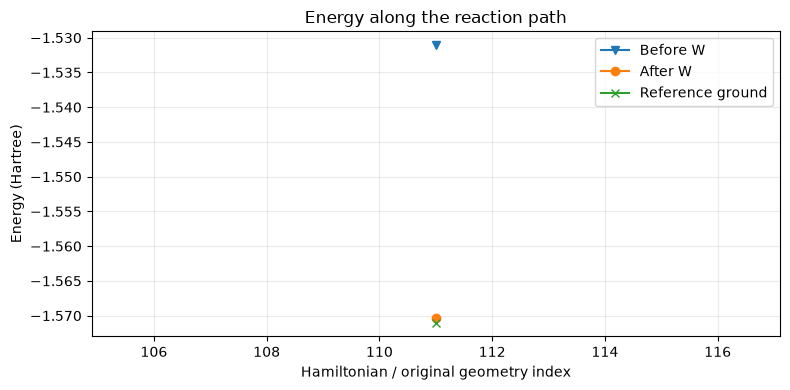

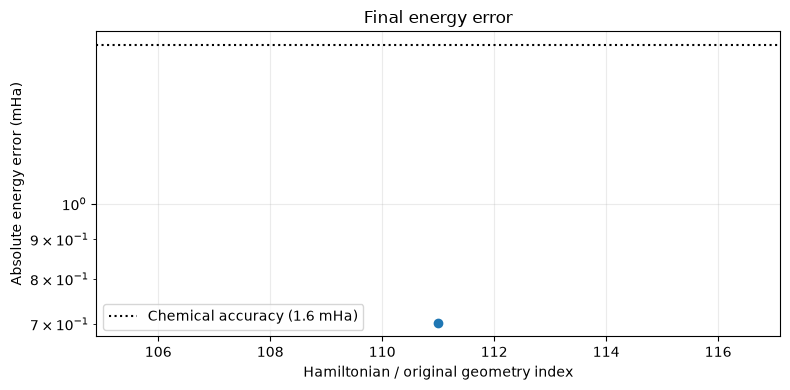

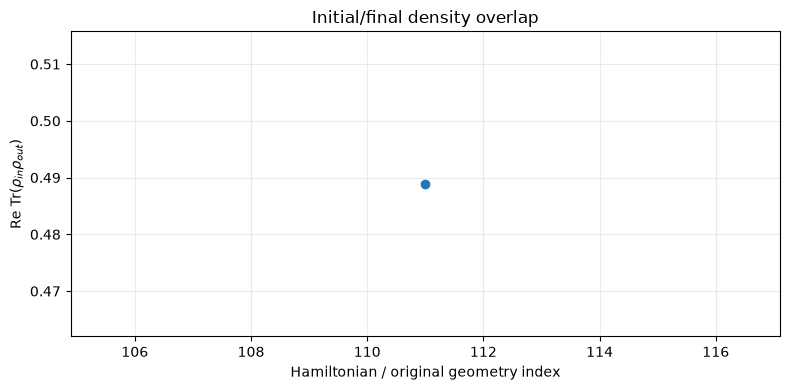

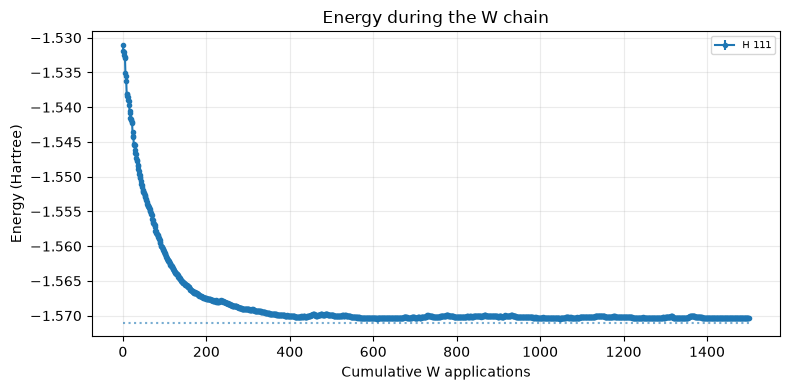

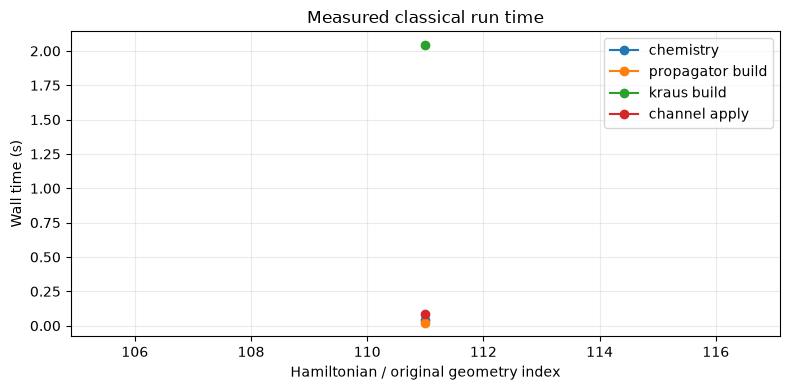

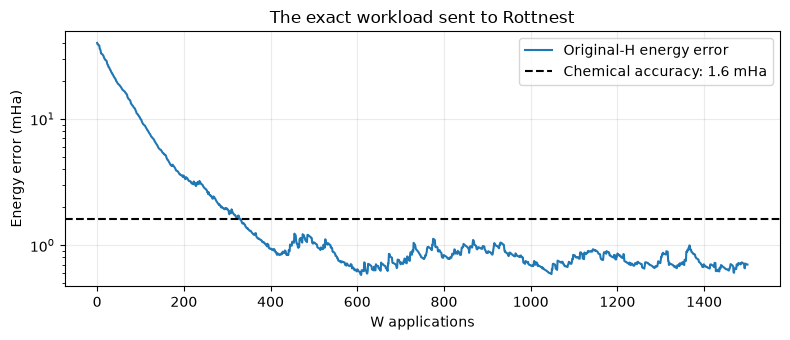

In [2]:
from collections import Counter
reaction = rxn.run_reaction(CONFIG)
first = reaction["geometries"][0]
# These are references to existing FrozenCircuits, not duplicated gate lists.
reaction_circuits = [g["factory"].circuit(i)
    for g in reaction["geometries"] for i in g["chain"]["sequence"]]
reaction_blocks = Counter()
frequency_rows = []
for g in reaction["geometries"]:
    reaction_blocks.update(one_ham.selected_block_counts(g["factory"],g["chain"]["sequence"]))
    for index,multiplicity in Counter(g["chain"]["sequence"]).items():
        frequency_rows.append({"frame":g["frame_index"],"jump":g["factory"].jumps[index].name,
                               "W multiplicity":multiplicity})
assert sum(reaction_blocks.values()) == len(reaction_circuits) == 1500
assert len(reaction_blocks) == 30
energy_rows = pd.DataFrame(reaction["energy_rows"])
energy_rows["error_mHa"] = 1000*(energy_rows.energy-energy_rows.target_energy)
final_error = float(energy_rows.error_mHa.iloc[-1])
first_below = int(energy_rows.loc[energy_rows.error_mHa<1.6,"step"].iloc[0])
assert final_error < 1.6
assert energy_rows.error_mHa.tail(500).max() < 1.6
print(f"Verified frame 111: final error {final_error:.6f} mHa; first crossing at W {first_below}.")
print(f"{len(reaction_circuits)} W applications represented by {len(reaction_blocks)} unique W blocks.")
display(pd.DataFrame(reaction["summary"]))
display(pd.DataFrame(frequency_rows))
figures = rxn.plot_results(reaction)
fig,ax = plt.subplots(figsize=(8,3.5))
ax.semilogy(energy_rows.step,energy_rows.error_mHa,label="Original-H energy error")
ax.axhline(1.6,color="black",ls="--",label="Chemical accuracy: 1.6 mHa")
ax.set(xlabel="W applications",ylabel="Energy error (mHa)",title="The exact workload sent to Rottnest")
ax.legend();ax.grid(alpha=.25);fig.tight_layout();plt.show()

## Hardware run
The installed Rottnest pipeline uses the Four Stage Superconducting architecture. `LAYOUT=None` uses its example layout; every result records the actual layout and error budgets.

Estimate **one W** and the **complete ordered 1,500-W sequence**. The complete sequence is scheduled directly through the cached block hierarchy; its runtime is not extrapolated by multiplying one-W runtime. Rottnest applies its synthesis/error-budget machinery to each supplied workload. A failure raises the worker log rather than substituting an estimate.

In [3]:
ARCHITECTURE = "Four Stage Superconducting"
LAYOUT = None
TIMEOUT_SECONDS = 7200
FULL_RUN = "converged geometry (1500 W)"
physical = {}
workloads = {"one W": [reaction_circuits[0]], FULL_RUN: reaction_circuits}
for label,circuits in workloads.items():
    print("Rottnest:", label, flush=True)
    physical[label] = one_ham.physical_resources(circuits, architecture=ARCHITECTURE,
        layout=LAYOUT, timeout=TIMEOUT_SECONDS)
    print("  T:", physical[label]["t_count"],
          "tocks:", physical[label]["hardware"]["tocks"]["total"], flush=True)
assert physical[FULL_RUN]["W_applications"] == len(reaction_circuits)

Rottnest: one W
  T: 464471864 tocks: 5014723936
Rottnest: converged geometry (1500 W)


TimeoutError: Rottnest exceeded 7200s.
Executing: preprocess_and_execute 0x11e7af9d0 -> preprocessor
Executing: preprocessor 0x109c37c90 -> hotswap_architecture
Executing: preprocessor 0x109c37c90 -> hotswap_layout
Executing: preprocessor 0x109c37c90 -> pool_procedure
Executing: pool_procedure 0x11fb602d0 -> patchers
Executing: patchers 0x11fb60390 -> Pyliqtr_Patches
Executing: patchers 0x11fb60390 -> Parser Tracking
Executing: pool_procedure 0x11fb602d0 -> Start Pool Manager
Executing: pool_procedure 0x11fb602d0 -> Reset Pool Context
Executing: pool_procedure 0x11fb602d0 -> Clear Buffers Before Job
Executing: pool_procedure 0x11fb602d0 -> Synch Pool
Executing: pool_procedure 0x11fb602d0 -> Start Pool
Executing: pool_procedure 0x11fb602d0 -> Run Pool
Executing: load_modules_procedure 0x11c2d5290 -> load_architectures
Executing: load_modules_procedure 0x11c2d5290 -> load_executables
Executing: load_modules_procedure 0x11c2d5650 -> load_architectures
Executing: load_modules_procedure 0x1

In [ ]:
summary = pd.DataFrame([{"workload":label,"W applications":r["W_applications"],
    "Rottnest Rz count":r["rz_count"], "Rottnest synthesized T count":r["t_count"],
    "Runtime (tocks)":r["hardware"]["tocks"]["total"],
    "Sum of reported region space-time volumes":sum(r["hardware"]["volumes"].values()),
    "Unique cached blocks":r["unique_cached_blocks"], "Classical estimation time (s)":r["seconds"]}
    for label,r in physical.items()]).set_index("workload")
display(summary)
print("Hardware assumptions for the converged run:")
display(pd.Series(physical[FULL_RUN]["assumptions"]))
print("Circuit manifest fingerprints:")
display(pd.Series({k:v["circuit_manifest_sha256"] for k,v in physical.items()}))

In [ ]:
fig,axes=plt.subplots(1,3,figsize=(14,4))
for ax,(title,key) in zip(axes,[("Runtime by stage (tocks)","tocks"),
                              ("Region space-time volumes","volumes"),
                              ("T states by factory source","t_source")]):
    table=pd.DataFrame({label:r["hardware"][key] for label,r in physical.items()}).T.fillna(0)
    table=table.loc[:,(table>0).any(axis=0)]
    table.plot.bar(ax=ax,stacked=False,rot=15,logy=True)
    ax.set_title(title);ax.set_ylabel("Log scale");ax.legend(fontsize=6)
fig.tight_layout();plt.show()
# Keep every returned value inspectable, in Rottnest's own names and units.
display(pd.json_normalize(list(physical.values())).set_axis(list(physical),axis=0))

## Relating logical and physical results
pyLIQTR's T estimate and Rottnest's synthesized T count use different synthesis/error-budget machinery. They need not be identical even for the same circuit. Compare the recorded precision assumptions before interpreting a difference as a bug. The repeated W blocks remain in both totals; caching reduces the classical estimation work.

The dissipative reaction requires an ancilla reset after each W. Energy measurements require separate copies of the prepared state, including repeated prefixes of the reaction circuit. Those costs must be added with a specified hardware reset/readout/state-preparation model before treating the numbers as a full experimental runtime.

In [ ]:
logical_same = one_ham.pyliqtr_resources(reaction_blocks,
    circuit_precision=CONFIG["logical_circuit_precision"])
assert logical_same["W_applications"] == 1500
assert logical_same["unique_W_blocks"] == 30
display(pd.Series(logical_same,name="pyLIQTR on exactly the Rottnest input sequence"))
display(pd.Series({"Required ancilla resets (not scheduled)":len(reaction_circuits),
    "Energy shots per term":CONFIG["energy_shots"],
    "Energy outputs here":"exact classical diagnostics",
    "Final verified energy error (mHa)":final_error,
    "Rottnest scope":physical[FULL_RUN]["scope"]},name="scope accounting"))

## HPC reuse
No new circuit generator is needed. Use the same Python environment with Cirq, OpenFermion, PySCF, pyLIQTR and the owner's installed Rottnest dependencies. Keep the six Python files together and copy the chosen reaction inputs.

```python
large = dict(rxn.USER_CONFIG, xyz_trajectory="path/to/trajectory.xyz",
             geometry_start=0, geometry_stop=2,
             simulate=False, spectral_method="bound",
             logical_resources=True, physical_resources=True,
             physical_timeout=7200, save_outputs="none")
# Configure the validated basis, spin, charge and active space before running.
# result = rxn.run_reaction(large)
# display(pd.DataFrame(result["summary"]))
# display(pd.json_normalize(result["physical"]))
# figures = rxn.plot_results(result)
```

`simulate=False` produces circuits, logical/physical resource and timing outputs without dense state simulation. Energy/overlap plots require tractable original and effective spaces: this driver uses dense original-space references and contextual state isometries. Low-energy calibration itself also requires an exact small-system reference; for larger builds use explicit low-rank/Pauli steps and do not label them certified low-energy counts.

The notebooks are portable front ends to the same functions as the HPC driver. `save_outputs="none"` leaves results in memory; a non-interactive batch terminal cannot display inline notebook figures.

When `logical_resources=True`, `result["logical_total"]` gives the whole-reaction count with one shared synthesis-error budget. Per-geometry rows have their own stated budget and must not be summed to infer that total.